# Stage 1 Data Analysis Athena

### Imports

In [25]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

### Check on Topics

#### Real Data

In [20]:
with open("data-real-athena/data-rear-axle/stage-1-test-left-1-rear-axle/stage-1-test-left-1-rear-axle.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

/rosout                                  rcl_interfaces/msg/Log                   18
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/tf                                      tf2_msgs/msg/TFMessage                   1649
/tf_static                               tf2_msgs/msg/TFMessage                   1
/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker geometry_msgs/msg/PoseStamped            1649
/commands/motor/speed                    std_msgs/msg/Float64                     48
/commands/servo/position                 std_msgs/msg/Float64                     48
/sensors/imu/raw                         sensor_msgs/msg/Imu                      445
/sensors/servo_position_command          std_msgs/msg/Float64                     48
/ackermann_cmd                           ackermann_msgs/msg/AckermannDriveStamped 70


#### Simulation Data

In [21]:
with open("data-sim-athena/data-rear-axle/stage-1-test-left-1-rear-axle/stage-1-test-left-1-rear-axle.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

/rosout                                  rcl_interfaces/msg/Log                   63
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/clicked_point                           geometry_msgs/msg/PointStamped           0
/move_base_simple/goal                   geometry_msgs/msg/PoseStamped            0
/initialpose                             geometry_msgs/msg/PoseWithCovarianceStamped 0
/odom                                    nav_msgs/msg/Odometry                    57
/tf                                      tf2_msgs/msg/TFMessage                   57
/topic                                   std_msgs/msg/Float32                     57
/ackermann_cmd                           ackermann_msgs/msg/AckermannDriveStamped 74


### Path Vicon Tracking vs Simulation

For booth the back axle was used

In [26]:


groups = ["left", "straight", "right"]
titles = {
    "left":     "left: 0.36 rad, 1 m/s",
    "straight": "straight: 0.0 rad, 1 m/s",
    "right":    "right: -0.36 rad, 1 m/s",
}
max_speed = 5.0
COLS = ["t", "t_log", "px", "py", "pz", "qx", "qy", "qz", "qw"]

VICON_TOPICS = [
    "/vicon/athena/athena",
    "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker",
]
YAW_OFFSET = {
    "/vicon/athena/athena": 0.0,
    "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker": np.pi / 2,
}
POSE_SCHEMAS = [
    "geometry_msgs/msg/PoseStamped",
    "nav_msgs/msg/Odometry",
    "geometry_msgs/msg/PoseWithCovarianceStamped",
    "geometry_msgs/msg/TransformStamped",
]
IGNORE_TOPICS = ("goal", "cmd", "target", "initial")


def find_base(name="stage-1-testing"):
    d = os.path.abspath(os.getcwd())
    while True:
        if os.path.basename(d) == name:
            return d
        for cand in (os.path.join(d, name), os.path.join(d, "sim-to-real-gap", name)):
            if os.path.isdir(cand):
                return cand
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError(f"'{name}' not found above {os.getcwd()}")
        d = parent


BASE = find_base()
SOURCES = {
    "real": dict(root=os.path.join(BASE, "data-real-athena", "data-rear-axle"),
                 topics=VICON_TOPICS,
                 yaw_offset=YAW_OFFSET,
                 drop_origin=True),
    "sim":  dict(root=os.path.join(BASE, "data-sim-athena", "data-rear-axle"),
                 topics=["/ground_truth/pose", "/odom"],
                 yaw_offset={},
                 drop_origin=False),
}
for src, cfg in SOURCES.items():
    print(f"{src:5s} {cfg['root']}  exists={os.path.isdir(cfg['root'])}")


def list_channels(path):
    with open(path, "rb") as f:
        summary = make_reader(f).get_summary()
    if summary is None:
        return {}
    counts = summary.statistics.channel_message_counts if summary.statistics else {}
    return {
        ch.topic: (summary.schemas[ch.schema_id].name, counts.get(ch_id))
        for ch_id, ch in summary.channels.items()
    }


def pick_topic(path, candidates):
    channels = list_channels(path)
    for t in candidates:
        if t in channels and channels[t][1] != 0:
            return t
    for schema_name in POSE_SCHEMAS:
        for t, (schema, count) in sorted(channels.items()):
            if schema == schema_name and count != 0 and not any(s in t.lower() for s in IGNORE_TOPICS):
                return t
    print(f"  no pose topic in {os.path.basename(path)}:")
    for t, (schema, count) in sorted(channels.items()):
        print(f"    {t:50s} {schema:45s} {count}")
    return None


def extract_pose(msg):
    if hasattr(msg, "pose"):
        pose = msg.pose.pose if hasattr(msg.pose, "pose") else msg.pose
        return pose.position, pose.orientation
    if hasattr(msg, "transform"):
        return msg.transform.translation, msg.transform.rotation
    raise TypeError(f"unknown message type: {type(msg)}")


def load_poses(path, topic):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _, _, message, msg in reader.iter_decoded_messages(topics=[topic]):
            p, q = extract_pose(msg)
            rows.append({
                "t": msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9,
                "t_log": message.log_time / 1e9,
                "px": p.x, "py": p.y, "pz": p.z,
                "qx": q.x, "qy": q.y, "qz": q.z, "qw": q.w,
            })
    if not rows:
        return pd.DataFrame(columns=COLS)
    df = pd.DataFrame(rows)
    if df["t"].nunique() < 0.5 * len(df):
        print(f"  header stamps unusable in {os.path.basename(path)}, using log time")
        df["t"] = df["t_log"]
    return df.sort_values("t").reset_index(drop=True)


def remove_jumps(df, max_speed=5.0, tol=0.01, origin_eps=1e-3, drop_origin=True):
    if df.empty:
        return df
    if drop_origin:
        at_origin = (df[["px", "py", "pz"]].abs() < origin_eps).all(axis=1)
        df = df[~at_origin].reset_index(drop=True)
        if df.empty:
            return df
    t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()
    keep = np.zeros(len(df), dtype=bool)
    keep[0] = True
    last = 0
    for i in range(1, len(df)):
        if np.hypot(x[i] - x[last], y[i] - y[last]) <= max_speed * (t[i] - t[last]) + tol:
            keep[i] = True
            last = i
    return df[keep].reset_index(drop=True)


def cut_at_gap(df, max_gap=0.2):
    if df.empty:
        return df
    gaps = np.where(df["t"].diff().to_numpy() > max_gap)[0]
    if len(gaps):
        df = df.iloc[:gaps[0]]
    return df.reset_index(drop=True)


def add_velocity(df, win=0.1):
    df = df.copy()
    t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()
    if len(t) < 3:
        df["vx"] = df["vy"] = np.nan
        return df
    k = max(1, int(round(win / 2 / np.median(np.diff(t)))))
    i = np.arange(len(t))
    lo, hi = np.clip(i - k, 0, len(t) - 1), np.clip(i + k, 0, len(t) - 1)
    dt = np.where(t[hi] > t[lo], t[hi] - t[lo], np.nan)
    df["vx"] = (x[hi] - x[lo]) / dt
    df["vy"] = (y[hi] - y[lo]) / dt
    return df


def quat_to_yaw(df):
    qw, qx, qy, qz = (df[k].to_numpy() for k in ["qw", "qx", "qy", "qz"])
    return np.arctan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy**2 + qz**2))


def align_start_src(df, topic, yaw_offset, n0=20):
    yaw = quat_to_yaw(df) + yaw_offset.get(topic, 0.0)
    yaw0 = np.arctan2(np.sin(yaw[:n0]).mean(), np.cos(yaw[:n0]).mean())
    dx = df["px"].to_numpy() - df["px"].iloc[0]
    dy = df["py"].to_numpy() - df["py"].iloc[0]
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    out = df.copy()
    out["ax"], out["ay"] = c * dx - s * dy, s * dx + c * dy
    return out


def load_source(src):
    cfg = SOURCES[src]
    dfs = {g: {} for g in groups}
    topic_of = {}
    for subdir, _, files in os.walk(cfg["root"]):
        for file in files:
            if not file.endswith(".mcap"):
                continue
            name = os.path.splitext(file)[0]
            m = re.search(r"(left|straight|right)-(\d+(?:-\d+)*)(?:-([a-z][\w-]*))?$", name)
            if not m:
                print(f"[{src}] skipped: {name}")
                continue
            group, run, tag = m.groups()
            if tag:
                run = f"{run} ({tag})"

            path = os.path.join(subdir, file)
            topic = pick_topic(path, cfg["topics"])
            if topic is None:
                continue

            df = load_poses(path, topic)
            n_before = len(df)
            df = remove_jumps(df, max_speed=max_speed, drop_origin=cfg["drop_origin"])
            df = cut_at_gap(df, max_gap=0.2)
            df = add_velocity(df)
            print(f"[{src}] {name}: {len(df)} msgs ({n_before - len(df)} removed) [{topic}]")

            if not df.empty:
                dfs[group][run] = df
                topic_of[(group, run)] = topic
    return dfs, topic_of


data, topics = {}, {}
for src in SOURCES:
    data[src], topics[src] = load_source(src)

print()
for src in SOURCES:
    for g in groups:
        print(f"{src:5s} {g:9s} {sorted(data[src][g])}")
if not any(data[src][g] for src in SOURCES for g in groups):
    raise RuntimeError("no runs loaded, check paths and topics above")

real  c:\Users\tommy\zhaw_local\autonomous_systems\athena\athena-data-analysis\sim-to-real-gap\stage-1-testing\data-real-athena\data-rear-axle  exists=True
sim   c:\Users\tommy\zhaw_local\autonomous_systems\athena\athena-data-analysis\sim-to-real-gap\stage-1-testing\data-sim-athena\data-rear-axle  exists=True
[real] stage-1-test-left-1-rear-axle: 1469 msgs (180 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-left-2-rear-axle: 1607 msgs (244 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-left-3-rear-axle: 1213 msgs (59 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-right-1-rear-axle: 1088 msgs (235 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-right-2-rear-axle: 1093 msgs (229 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-right-3-rear-axle: 1240 msgs (245 removed) [/vicon/at

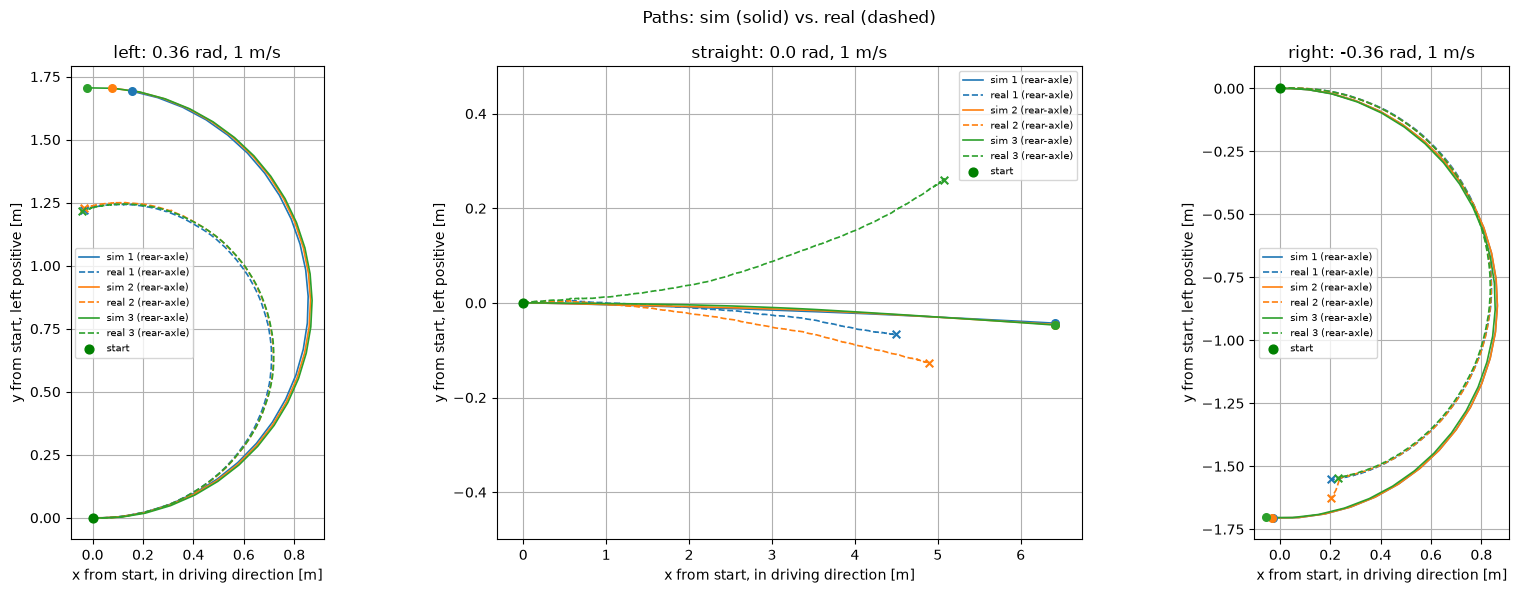

In [29]:
v_min = 0.5
STYLE = {"sim": "-", "real": "--"}
colors = plt.cm.tab10.colors
CROP_TO_REAL = True


def departure_index(df, v_min):
    v = np.hypot(df["vx"], df["vy"]).to_numpy()
    idx = np.flatnonzero(v > v_min)
    return int(idx[0]) if idx.size else None


def align_at_departure(df, topic, yaw_offset, v_min=0.5, t_yaw=0.1):
    i0 = departure_index(df, v_min)
    if i0 is None:
        return None
    i0 = max(i0 - 1, 0)
    df = df.iloc[i0:].reset_index(drop=True)
    t = df["t"].to_numpy() - df["t"].iloc[0]
    yaw = quat_to_yaw(df) + yaw_offset.get(topic, 0.0)
    w = t <= t_yaw
    yaw0 = np.arctan2(np.sin(yaw[w]).mean(), np.cos(yaw[w]).mean())
    dx = df["px"].to_numpy() - df["px"].iloc[0]
    dy = df["py"].to_numpy() - df["py"].iloc[0]
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    out = df.copy()
    out["tt"] = t
    out["ax"], out["ay"] = c * dx - s * dy, s * dx + c * dy
    return out


aligned = {src: {g: {} for g in groups} for src in SOURCES}
for src in SOURCES:
    for g in groups:
        for run, df in data[src][g].items():
            a = align_at_departure(df, topics[src][(g, run)], SOURCES[src]["yaw_offset"], v_min)
            if a is None:
                print(f"[{src}] {g} {run}: never faster than {v_min} m/s, skipped")
                continue
            aligned[src][g][run] = a

t_max = {g: max((a["tt"].iloc[-1] for a in aligned["real"][g].values()), default=np.inf)
         for g in groups}


def get_run(src, g, run):
    a = aligned[src][g][run]
    if CROP_TO_REAL and src == "sim":
        a = a[a["tt"] <= t_max[g]]
    return a


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, g in zip(axes, groups):
    runs = sorted(set(aligned["sim"][g]) | set(aligned["real"][g]))
    for i, run in enumerate(runs):
        c = colors[i % len(colors)]
        for src in ["sim", "real"]:
            if run not in aligned[src][g]:
                continue
            a = get_run(src, g, run)
            ax.plot(a["ax"], a["ay"], STYLE[src], color=c, lw=1.2, label=f"{src} {run}")
            ax.scatter(a["ax"].iloc[-1], a["ay"].iloc[-1], color=c,
                       marker="x" if src == "real" else "o", s=30, zorder=3)
    ax.scatter(0, 0, color="green", s=40, zorder=4, label="start")
    ax.set_title(titles[g])
    ax.set_xlabel("x from start, in driving direction [m]")
    ax.set_ylabel("y from start, left positive [m]")
    if g == "straight":
        ax.set_ylim(-0.5, 0.5)
    else:
        ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=7)
fig.suptitle("Paths: sim (solid) vs. real (dashed)")
plt.tight_layout()
plt.show()

### Speed Vicon Tracking vs Simulation

For booth the back axle was used

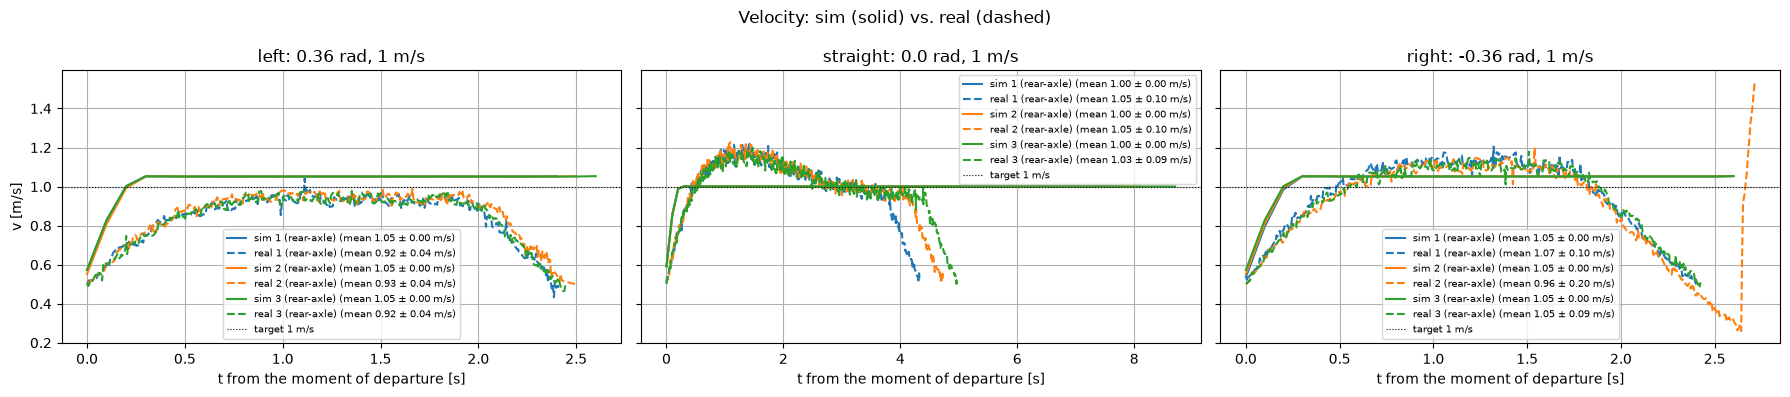

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    runs = sorted(set(aligned["sim"][g]) | set(aligned["real"][g]))
    for i, run in enumerate(runs):
        c = colors[i % len(colors)]
        for src in ["sim", "real"]:
            if run not in aligned[src][g]:
                continue
            a = get_run(src, g, run)
            t = a["tt"].to_numpy()
            v = np.hypot(a["vx"], a["vy"]).to_numpy()
            idx = np.flatnonzero(v > v_min)
            if idx.size == 0:
                continue
            t, v = t[:idx[-1] + 1], v[:idx[-1] + 1]
            steady = (t > 0.7) & (t < t[-1] - 0.3)
            label = f"{src} {run}"
            if steady.any():
                label += f" (mean {v[steady].mean():.2f} ± {v[steady].std():.2f} m/s)"
            ax.plot(t, v, STYLE[src], color=c, label=label)
    ax.axhline(1.0, color="k", ls=":", lw=0.8, label="target 1 m/s")
    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=7)
axes[0].set_ylabel("v [m/s]")
fig.suptitle("Velocity: sim (solid) vs. real (dashed)")
plt.tight_layout()
plt.show()